In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import torch


import torch

from core.toy_transformer import ToyTransformer
from core.number_line import NumberLine

# Starter sandbox with number line task

Let's see if we can replicate the basic finding from the number line task:

1. Initialize a "ground truth" number line with d items
2. Add an *operator* to that number line (RIGHT OF(a,b)) 
3. Sample n observations of RIGHT OF(a,b) and train a toy transformer on those observations (with some amount of skew (alpha))
4. Add a new item to the number line and transformer vocabulary
5. Train on that item (additional RIGHT OF() presentations where all isntances contain the new items)

With *low alpha* (low skew) we expect: high accuracy on the train set, low accuracy on incorporating the new item
With *high alpha* (high skew): low acc. on train test, high accuracy on the new item.

### 1. Initialize number line
We'll start by initializing our number line with d (100 items) and zero skew. NumberLine tracks our vocab items, operators and truth states(TRUE/FALSE).

In [ ]:
D_TASK = 100

line = NumberLine(d=D_TASK, alpha=0.0, distinct_operands=True, seed=999)


### 2. Add operator to the number line
Next we'll add our operator. This can be any sort of callback fn which can compare items in the list based on their position.

In [ ]:
def right_of(a, b):
    return a > b

line.add_operator_token("RIGHT_OF", right_of, arity=2)


{'name': 'RIGHT_OF',
 'fn': <function __main__.right_of(a, b)>,
 'arity': 2,
 'weight': 1.0}

### 3. Loop to train over various levels of alpha

I'll skip over some things here, but we'll just repeat the above steps for several values of alpha.

In [6]:
d_task = 100 # number of vocab embeddings
n_train = 2000 #number of observations drawn from distribution

batch_size = 64 
epochs = 20 #number of times each observation is trained on
lr = 3e-4
n_eval = 2000 #number of test observations (always sampled uniformly)
model_seed = 0

n_new_items = 1 # number of new items
n_new_train = 5 #training instances with new item
new_epochs = 1

alphas = [0.0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1.0, 1.5, 2.0]#range of zipf alphas

In [ ]:



torch.manual_seed(model_seed)
model = ToyTransformer("qwen2", d_model=128, n_layers=3, n_heads=4, n_ctx=64) #init transformer

results = {}
for k, alpha in enumerate(alphas):
    line = NumberLine(d=D_TASK, alpha=alpha, distinct_operands=True, seed=k) #init numberline
    line.add_operator_token("RIGHT_OF", right_of, arity=2) #add operator

    torch.manual_seed(model_seed)
    model.reset()
    model.add_task("numberline", tokens=line.vocab, alpha=alpha) #add numberline task to model

    eval_data = model.get_eval_set(line, n_eval) #get eval set (uniform)

    line.reset_counts()
    model.fit(line.training_instances(n_train), epochs=epochs, batch_size=batch_size, lr=lr) #fit model
    base_acc = model.accuracy(eval_data)
    seen = sum(1 for t in line.items if line.token_counts[t] > 0)

    new_items = line.add_new_item_token(
        [f"new{i}" for i in range(n_new_items)], ranks=list(range(n_new_items))
    )
    model.add_tokens(new_items)

    new_seqs = []
    while len(new_seqs) < n_new_train:
        seq = line.make_instance("RIGHT_OF", distinct=True)
        if seq[1] in new_items or seq[2] in new_items:
            new_seqs.append(seq)
    new_eval = [
        s
        for s in line.training_instances(n_eval)
        if s[1] in new_items or s[2] in new_items
    ]

    before = model.accuracy(new_eval)
    model.fit(new_seqs, epochs=new_epochs, batch_size=batch_size, lr=lr)
    after = model.accuracy(new_eval)
    retention = model.accuracy(eval_data)

    results[alpha] = (base_acc, seen, before, after, retention)
    print(
        f"alpha {alpha:<4} | base accuracy: {base_acc:.3f} |  % items seen {seen}/{d_task} | novel token accuracy: {after:.3f}   "
    )



alpha 0.0  base 0.947  seen 100/100  new before 0.444  new after 0.500  retention 0.934
alpha 0.1  base 0.919  seen 100/100  new before 0.530  new after 0.561  retention 0.911
alpha 0.2  base 0.925  seen 100/100  new before 0.403  new after 0.403  retention 0.922
alpha 0.3  base 0.936  seen 100/100  new before 0.534  new after 0.526  retention 0.939
alpha 0.4  base 0.920  seen 100/100  new before 0.571  new after 0.577  retention 0.924
alpha 0.5  base 0.909  seen 100/100  new before 0.569  new after 0.653  retention 0.897
alpha 0.6  base 0.900  seen 100/100  new before 0.652  new after 0.748  retention 0.879
alpha 0.7  base 0.872  seen 100/100  new before 0.590  new after 0.699  retention 0.861
alpha 0.8  base 0.867  seen 100/100  new before 0.672  new after 0.446  retention 0.848
alpha 0.9  base 0.800  seen 100/100  new before 0.677  new after 0.666  retention 0.792
alpha 1.0  base 0.778  seen 100/100  new before 0.624  new after 0.761  retention 0.774
alpha 1.5  base 0.526  seen 94/1

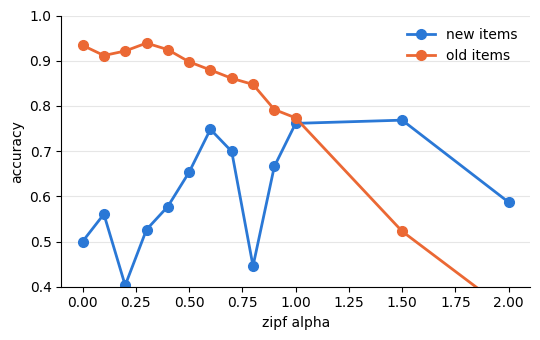

In [8]:
import matplotlib.pyplot as plt

xs = list(results)
new_after = [results[a][3] for a in xs]
retention = [results[a][4] for a in xs]

fig, ax = plt.subplots(figsize=(5.5, 3.5))
ax.plot(xs, new_after, color="#2a78d6", lw=2, marker="o", ms=7, label="new items")
ax.plot(xs, retention, color="#eb6834", lw=2, marker="o", ms=7, label="old items")

ax.set_xlabel("zipf alpha")
ax.set_ylabel("accuracy")
ax.set_ylim(0.4, 1.0)
ax.grid(axis="y", color="0.9", lw=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()


Results as expected! let's try for one other operator

In [18]:
def ordering(a, b, c):
    return abs(b - a) < abs(c - a)




In [ ]:
d_task = 100 # number of vocab embeddings
n_train = 4000 #number of observations drawn from distribution

batch_size = 64 
epochs = 40 #number of times each observation is trained on
lr = 3e-4
n_eval = 2000 #number of test observations (always sampled uniformly)
model_seed = 0

n_new_items = 1 # number of new items
n_new_train = 5 #training instances with new item
new_epochs = 10

alphas = [0.0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1.0]

In [23]:



torch.manual_seed(model_seed)
model = ToyTransformer("qwen2", d_model=128, n_layers=3, n_heads=4, n_ctx=64) #init transformer

results = {}
for k, alpha in enumerate(alphas):
    line = NumberLine(d=D_TASK, alpha=alpha, distinct_operands=True, seed=k) #init numberline
    line.add_operator_token("ORDERING", ordering, arity=3) #add operator

    torch.manual_seed(model_seed)
    model.reset()
    model.add_task("numberline", tokens=line.vocab, alpha=alpha) #add numberline task to model

    eval_data = model.get_eval_set(line, n_eval) #get eval set (uniform)

    line.reset_counts()
    model.fit(line.training_instances(n_train), epochs=epochs, batch_size=batch_size, lr=lr) #fit model
    base_acc = model.accuracy(eval_data)
    seen = sum(1 for t in line.items if line.token_counts[t] > 0)

    new_items = line.add_new_item_token(
        [f"new{i}" for i in range(n_new_items)], ranks=list(range(n_new_items))
    )
    model.add_tokens(new_items)

    new_seqs = []
    while len(new_seqs) < n_new_train:
        seq = line.make_instance("ORDERING", distinct=True)
        if seq[1] in new_items or seq[2] in new_items:
            new_seqs.append(seq)
    new_eval = [
        s
        for s in line.training_instances(n_eval)
        if s[1] in new_items or s[2] in new_items
    ]

    before = model.accuracy(new_eval)
    model.fit(new_seqs, epochs=new_epochs, batch_size=batch_size, lr=lr)
    after = model.accuracy(new_eval)
    retention = model.accuracy(eval_data)

    results[alpha] = (base_acc, seen, before, after, retention)
    print(
        f"alpha {alpha:<4} | base accuracy: {base_acc:.3f} |  % items seen {seen}/{d_task} | novel token accuracy: {after:.3f}   "
    )



alpha 0.0  | base accuracy: 0.762 |  % items seen 100/100 | novel token accuracy: 0.535   
alpha 0.1  | base accuracy: 0.769 |  % items seen 100/100 | novel token accuracy: 0.650   
alpha 0.2  | base accuracy: 0.752 |  % items seen 100/100 | novel token accuracy: 0.411   
alpha 0.3  | base accuracy: 0.793 |  % items seen 100/100 | novel token accuracy: 0.546   
alpha 0.4  | base accuracy: 0.750 |  % items seen 100/100 | novel token accuracy: 0.452   


KeyboardInterrupt: 

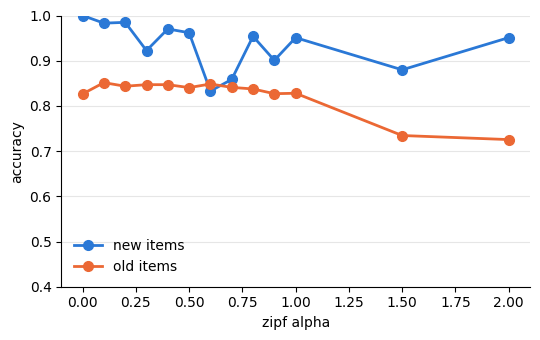

In [ ]:
import matplotlib.pyplot as plt

xs = list(results)
new_after = [results[a][3] for a in xs]
retention = [results[a][4] for a in xs]

fig, ax = plt.subplots(figsize=(5.5, 3.5))
ax.plot(xs, new_after, color="#2a78d6", lw=2, marker="o", ms=7, label="new items")
ax.plot(xs, retention, color="#eb6834", lw=2, marker="o", ms=7, label="old items")

ax.set_xlabel("zipf alpha")
ax.set_ylabel("accuracy")
ax.set_ylim(0.4, 1.0)
ax.grid(axis="y", color="0.9", lw=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()
